#Customer Churn / Sales Trend Analysis

## 1. Project Overview

This project focuses on analysing e-commerce sales data to identify monthly revenue trends, high-performing product categories, and the most valuable customers. The analysis will use Python, Pandas, NumPy, Matplotlib, and Seaborn to generate meaningful business insights and data-driven recommendations.

## 2. Business Questions

1. Which months generate the highest and lowest revenue, and how does revenue change over time?
2. Which product categories perform best based on total revenue, average order value, and order count?
3. Who are the most valuable customers, and what percentage of total revenue comes from the top 10% of customers?

## 3. Project Objective

To analyse e-commerce sales data, identify important business patterns, evaluate customer spending behaviour, and provide actionable recommendations supported by numerical findings.

## 4. Importing Required Libraries

In this step, we import the Python libraries required for data generation, data manipulation, and numerical analysis.

In [1]:
import numpy as np
import pandas as pd

print("Libraries imported successfully!")

Libraries imported successfully!


## 5. Creating the E-commerce Sales Dataset

A simulated e-commerce sales dataset is generated containing 2,000 orders, 300 customers, four product categories, order dates, and purchase amounts. The dataset is created using NumPy and Pandas.

In [2]:
# Set random seed for reproducibility
rng = np.random.default_rng(42)

# Number of orders
n = 2000

# Generate sample e-commerce sales data
orders = pd.DataFrame({
    "order_date": pd.to_datetime("2025-01-01") +
                  pd.to_timedelta(
                      rng.integers(0, 365, n),
                      unit="D"
                  ),

    "customer_id": rng.integers(1, 301, n),

    "category": rng.choice(
        ["Electronics", "Fashion", "Home", "Books"],
        n,
        p=[0.3, 0.35, 0.2, 0.15]
    ),

    "amount": rng.gamma(2.0, 600, n).round(2)
})

print("Dataset created successfully!")

Dataset created successfully!


### 5.1 Preview of the Dataset

The first five records are displayed to understand the structure and contents of the generated sales dataset.

In [3]:
orders.head()

,order_date,customer_id,category,amount
0,2025-02-02,264,Home,391.13
1,2025-10-10,19,Fashion,2456.21
2,2025-08-27,120,Books,674.90
3,2025-06-10,138,Home,75.38
4,2025-06-08,240,Electronics,774.42


### 5.2 Dataset Structure and Quality Check

The dataset shape, column data types, missing values, and duplicate records are examined to understand the quality and structure of the data.

In [4]:
print("Dataset Shape:", orders.shape)

print("\nDataset Information:")
orders.info()

print("\nMissing Values:")
print(orders.isnull().sum())

print("\nDuplicate Rows:")
print(orders.duplicated().sum())

Dataset Shape: (2000, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_date   2000 non-null   datetime64[ns]
 1   customer_id  2000 non-null   int64         
 2   category     2000 non-null   object        
 3   amount       2000 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 62.6+ KB

Missing Values:
order_date     0
customer_id    0
category       0
amount         0
dtype: int64

Duplicate Rows:
0


### 5.3 Data Quality Summary

The generated dataset contains 2,000 records and four columns. All columns have appropriate data types. The quality check identified no missing values and no duplicate rows. Therefore, the dataset is ready for further analysis.

## 6. Feature Engineering and Date Extraction

Feature engineering is performed to extract useful time-based information from the order date. New features such as month, weekday, and quarter are created to support monthly sales trend analysis.

In [5]:
# Convert order_date into datetime format
orders["order_date"] = pd.to_datetime(orders["order_date"])

# Extract month
orders["month"] = orders["order_date"].dt.to_period("M")

# Extract weekday
orders["weekday"] = orders["order_date"].dt.day_name()

# Extract quarter
orders["quarter"] = orders["order_date"].dt.quarter

print("Date features created successfully!")

Date features created successfully!


In [6]:
# Display the updated dataset
display(orders.head(10))

# Display all column names
print("Updated Columns:")
print(orders.columns.tolist())

,order_date,customer_id,category,amount,month,weekday,quarter
0,2025-02-02,264,Home,391.13,2025-02,Sunday,1
1,2025-10-10,19,Fashion,2456.21,2025-10,Friday,4
2,2025-08-27,120,Books,674.90,2025-08,Wednesday,3
3,2025-06-10,138,Home,75.38,2025-06,Tuesday,2
4,2025-06-08,240,Electronics,774.42,2025-06,Sunday,2
5,2025-11-10,39,Books,1181.46,2025-11,Monday,4
6,2025-02-01,131,Fashion,1271.72,2025-02,Saturday,1
7,2025-09-12,46,Electronics,366.39,2025-09,Friday,3
8,2025-03-15,237,Electronics,1009.72,2025-03,Saturday,1
9,2025-02-04,190,Home,1745.32,2025-02,Tuesday,1


Updated Columns:
['order_date', 'customer_id', 'category', 'amount', 'month', 'weekday', 'quarter']


###Date Feature Extraction Results

Three new time-based features were successfully created: month, weekday, and quarter. These features help identify monthly revenue patterns, weekday order distribution, and quarterly sales performance.

## 7. Monthly Revenue Trend Analysis

### 7.1 Monthly Revenue Analysis

Monthly revenue analysis is performed to understand the sales performance of the business throughout the year. The total revenue generated from orders is calculated for each month using the order date and sales amount. This analysis helps identify monthly sales patterns and understand how revenue changes over time.

In [7]:
# Calculate total revenue for each month
monthly_revenue = (
    orders.groupby("month")["amount"]
    .sum()
    .sort_index()
)

# Calculate month-over-month growth percentage
monthly_growth = monthly_revenue.pct_change() * 100

# Combine revenue and growth into one table
monthly_analysis = pd.DataFrame({
    "Total Revenue": monthly_revenue,
    "MoM Growth (%)": monthly_growth
})

# Display monthly analysis
display(monthly_analysis.round(2))

,Total Revenue,MoM Growth (%)
month,,
2025-01,193341.87,NaN
2025-02,232027.20,20.01
2025-03,206327.14,-11.08
2025-04,197310.20,-4.37
2025-05,194090.49,-1.63
2025-06,221889.83,14.32
2025-07,221813.81,-0.03
2025-08,179783.75,-18.95
2025-09,180569.95,0.44


### 7.2 Month-over-Month (MoM) Growth Analysis

Month-over-Month growth analysis is used to measure the percentage increase or decrease in revenue compared with the previous month. This calculation helps evaluate monthly business performance and identify periods of revenue growth or decline. It also provides useful information for understanding changes in sales over time.

### 7.3 Highest and Lowest Revenue Month

The monthly revenue results are examined to identify the month with the highest revenue and the month with the lowest revenue. Identifying these months helps understand the strongest and weakest sales periods of the business. These findings can support better planning of marketing campaigns, inventory, and promotional activities.

In [8]:
# Identify the month with the highest revenue
best_month = monthly_revenue.idxmax()
best_revenue = monthly_revenue.max()

# Identify the month with the lowest revenue
worst_month = monthly_revenue.idxmin()
worst_revenue = monthly_revenue.min()

print("Best Revenue Month:", best_month)
print("Highest Revenue:", round(best_revenue, 2))

print("\nWorst Revenue Month:", worst_month)
print("Lowest Revenue:", round(worst_revenue, 2))

Best Revenue Month: 2025-02
Highest Revenue: 232027.2

Worst Revenue Month: 2025-08
Lowest Revenue: 179783.75


### 7.4 Monthly Revenue Trend Visualization

A line chart is created to visualize monthly revenue throughout the year. The visualization highlights changes in revenue across different months and makes it easier to identify sales trends. The highest and lowest revenue months are also highlighted to provide a clear comparison of business performance.

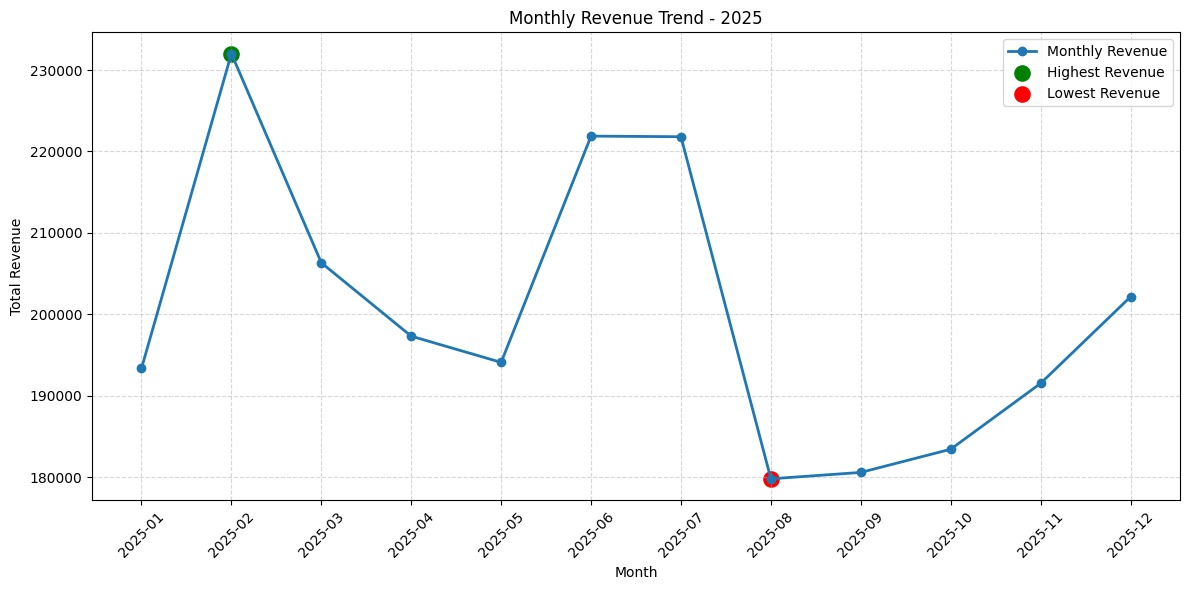

In [9]:
import matplotlib.pyplot as plt

# Create the figure
plt.figure(figsize=(12, 6))

# Plot monthly revenue
plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o",
    linewidth=2,
    label="Monthly Revenue"
)

# Highlight the best revenue month
plt.scatter(
    str(best_month),
    best_revenue,
    color="green",
    s=120,
    label="Highest Revenue"
)

# Highlight the worst revenue month
plt.scatter(
    str(worst_month),
    worst_revenue,
    color="red",
    s=120,
    label="Lowest Revenue"
)

# Add chart title and labels
plt.title("Monthly Revenue Trend - 2025")
plt.xlabel("Month")
plt.ylabel("Total Revenue")

# Improve chart readability
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()

# Display the chart
plt.show()

### 7.5 Monthly Revenue Trend Observation

The monthly revenue analysis provides insights into the sales performance of the business throughout the year. Month-over-Month growth percentages help identify changes in revenue compared with previous months. The highest and lowest revenue months highlight variations in sales performance and provide useful insights for future business planning.

## 8. Category Performance Analysis

Category performance analysis is conducted to identify the best-performing product categories. Total revenue, average order value, and order count are calculated to compare category-wise sales performance.

### 8.1 Category-wise Sales Performance

Category-wise sales performance is analysed by calculating total revenue, average order value, and the number of orders for each product category. This helps compare the sales performance of different categories.

In [10]:
# Calculate category-wise sales performance
category_analysis = (
    orders.groupby("category")["amount"]
    .agg(
        Total_Revenue="sum",
        Average_Order_Value="mean",
        Number_of_Orders="count"
    )
    .sort_values("Total_Revenue", ascending=False)
)

# Display category analysis
display(category_analysis.round(2))

,Total_Revenue,Average_Order_Value,Number_of_Orders
category,,,
Fashion,853984.93,1219.98,700
Electronics,722645.53,1163.68,621
Home,464114.66,1218.15,381
Books,363488.17,1219.76,298


### 8.2 Monthly Revenue by Product Category

A pivot table is created to compare monthly revenue across different product categories. This helps identify how each category contributes to revenue over time.

In [11]:
# Create a monthly revenue pivot table
monthly_category_pivot = pd.pivot_table(
    orders,
    values="amount",
    index="month",
    columns="category",
    aggfunc="sum",
    fill_value=0
)

# Display the pivot table
display(monthly_category_pivot.round(2))

category,Books,Electronics,Fashion,Home
month,,,,
2025-01,29186.89,62841.89,64665.99,36647.10
2025-02,34034.13,53564.89,86123.31,58304.87
2025-03,27843.58,58055.95,75138.67,45288.94
2025-04,26593.72,83335.56,57057.72,30323.20
2025-05,34425.63,57219.16,68569.90,33875.80
2025-06,32936.76,60037.00,85598.09,43317.98
2025-07,35582.36,72649.65,72647.96,40933.84
2025-08,32550.65,56690.46,71251.54,19291.10
2025-09,21824.73,60388.56,60231.75,38124.91


### 8.3 Best Performing Category

The category generating the highest total revenue is identified to understand which product category contributes the most to overall sales.

In [12]:
# Identify the category with the highest total revenue
top_category = category_analysis["Total_Revenue"].idxmax()

top_category_revenue = category_analysis["Total_Revenue"].max()

print("Best Performing Category:", top_category)
print("Total Revenue:", round(top_category_revenue, 2))

Best Performing Category: Fashion
Total Revenue: 853984.93


### 8.4 Category Performance Observations

The category-wise analysis compares total revenue, average order value, and order count across product categories. The monthly pivot table provides additional insights into category-wise revenue patterns over time.

### 8.5 Category Performance Summary

The overall category performance is summarised using revenue contribution percentages. This helps identify the importance of each product category in total business revenue.

In [13]:
# Display the category with the highest revenue
print("Highest Revenue Category:", top_category)

# Display category-wise revenue contribution
category_contribution = (
    category_analysis["Total_Revenue"] /
    category_analysis["Total_Revenue"].sum()
) * 100

print("\nRevenue Contribution by Category:")
display(category_contribution.round(2))

Highest Revenue Category: Fashion

Revenue Contribution by Category:


,Total_Revenue
category,
Fashion,35.52
Electronics,30.06
Home,19.30
Books,15.12


The category revenue analysis shows that Fashion is the leading category, contributing 35.52% of total revenue. Electronics contributes 30.06%, followed by Home at 19.30% and Books at 15.12%. These results indicate that Fashion and Electronics together account for 65.58% of total revenue.

## 9. Best Customer Analysis (Pareto 80/20)
### 9.1 Customer-wise Spending Analysis
Customer-wise spending analysis is performed to identify the most valuable customers. Total spending is calculated for each customer and sorted in descending order to identify the highest-spending customers.

In [14]:
customer_spending = (
    orders.groupby("customer_id")["amount"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Number of Active Customers:", len(customer_spending))

print("\nTop 10 Highest-Spending Customers:")
display(customer_spending.head(10).round(2))

Total Number of Active Customers: 300

Top 10 Highest-Spending Customers:


,amount
customer_id,
226,18140.15
51,18126.28
53,17994.36
131,17639.25
185,17222.49
282,17161.00
121,16564.87
98,15351.48
255,15313.47


### 9.2 Top 10% Customer Revenue Contribution

The top 10% of customers are identified based on their total spending. Their combined revenue is compared with overall revenue to calculate their contribution percentage. This analysis helps evaluate the Pareto 80/20 principle.

In [15]:
import math

top_10_count = math.ceil(len(customer_spending) * 0.10)

top_10_customers = customer_spending.head(top_10_count)

top_10_revenue = top_10_customers.sum()
total_revenue = customer_spending.sum()

top_10_percentage = (top_10_revenue / total_revenue) * 100

print("Total Active Customers:", len(customer_spending))
print("Top 10% Customer Count:", top_10_count)
print("Revenue from Top 10% Customers:", round(top_10_revenue, 2))
print("Total Revenue:", round(total_revenue, 2))
print("Top 10% Revenue Contribution:", round(top_10_percentage, 2), "%")

Total Active Customers: 300
Top 10% Customer Count: 30
Revenue from Top 10% Customers: 455331.97
Total Revenue: 2404233.29
Top 10% Revenue Contribution: 18.94 %


### 9.3 Top Customer Revenue Visualization

A bar chart is used to visualize the spending of the top 10 highest-value customers. This helps compare customer spending and identify the most valuable customers.

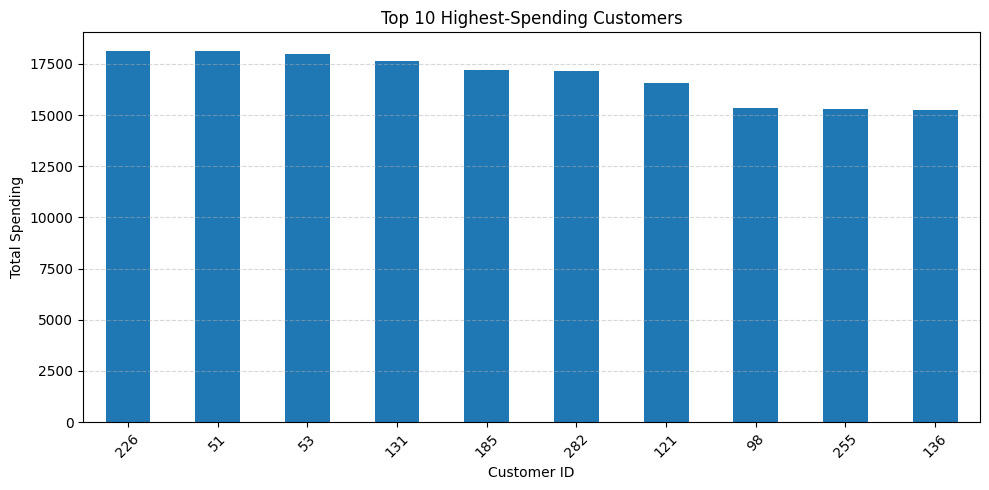

In [16]:
import matplotlib.pyplot as plt

top_10_customers.head(10).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 Highest-Spending Customers")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 9.4 Pareto Analysis – Key Findings

The customer analysis identified 300 active customers. The top 10% (30 customers) generated 455,331.97 in revenue, contributing 18.94% of total revenue. The remaining 90% of customers contributed 81.06%. Therefore, the results do not follow the traditional 80/20 pattern, indicating that revenue is distributed across a larger customer base.

## 10. Business Recommendations

### 10.1 Introduction
Based on the e-commerce sales analysis, three data-driven business recommendations are proposed. These recommendations focus on improving category performance, strengthening customer retention, and increasing revenue opportunities.

### 10.2 Focus on High-Revenue Categories

Fashion contributes 35.52% of total revenue, while Electronics contributes 30.06%. Together, these categories generate 65.58% of total revenue. The business should prioritize marketing campaigns, product availability, and promotional offers for these two categories to strengthen its major revenue sources.

### 10.3 Improve Customer Retention

The top 10% of customers contribute 18.94% of total revenue. The business should introduce loyalty rewards, personalized offers, and exclusive discounts for its top 30 customers to encourage repeat purchases and improve customer retention.

### 10.4 Improve Lower-Revenue Categories

Home and Books contribute 19.30% and 15.12% of total revenue, respectively. Together, they account for 34.42%. The business should analyse customer preferences, review product demand, and introduce targeted promotions to improve sales in these categories.

### 10.5 Business Recommendations Summary

1. Prioritize Fashion and Electronics, which contribute 65.58% of revenue.
2. Introduce loyalty programs for the top 30 customers, who generate 18.94% of revenue.
3. Improve Home and Books category sales through targeted promotions, as they contribute 34.42% of revenue.

## 11. Project Conclusion

### 11.1 Conclusion

This project analysed an e-commerce sales dataset containing 2,000 orders and 300 active customers. Monthly revenue trends, category performance, and customer spending patterns were examined using Python, Pandas, NumPy, and Matplotlib.

The analysis identified Fashion as the highest revenue-generating category, contributing 35.52% of total revenue, followed by Electronics at 30.06%. The top 10% of customers contributed 18.94% of overall revenue. Three data-driven business recommendations were proposed to improve category performance, customer retention, and sales growth.

Overall, this project demonstrates how data analysis can transform raw sales data into meaningful business insights and support better decision-making.

### 11.2 Project Skills and Tools Used

- Python – Data analysis and calculations
- Pandas – Data manipulation and aggregation
- NumPy – Dataset generation and numerical operations
- Matplotlib – Data visualization
- Exploratory Data Analysis (EDA)
- Feature Engineering and Date Extraction
- Business Insights and Recommendations